# Time Series Modeling

This notebook accompanies the note [time series modeling](../../notes/time_series/time_series_modeling.md). Modeling is iterative: specify, estimate, diagnose, and validate on future-like data. We reproduce the note's calculations and run a compact end-to-end workflow:

1. AIC / BIC / AICc for two candidates (the note's $-100$ versus $-96$ example);
2. the six-point AR(2) least-squares fit and its explosive recursion;
3. a rank-deficient design matrix;
4. order selection and estimation on simulated AR(2) data;
5. residual diagnostics (ACF, Ljung-Box);
6. chronological holdout evaluation against baselines.

## 1. Information criteria for two candidates

Model A has $\ell=-100$ with $k=3$ parameters; model B has $\ell=-96$ with $k=6$. With $\mathrm{AIC}=-2\ell+2k$: $\mathrm{AIC}_A=206$, $\mathrm{AIC}_B=204$. BIC adds $k\log n$ and AICc adds $2k(k+1)/(n-k-1)$, so conclusions can depend on the sample size $n$.

In [1]:
%matplotlib inline
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import matplotlib.pyplot as plt
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.ar_model import AutoReg
from statsmodels.tsa.stattools import acf
from statsmodels.stats.diagnostic import acorr_ljungbox

models = {"A": (-100.0, 3), "B": (-96.0, 6)}
print("AIC:", {m: -2 * l + 2 * k for m, (l, k) in models.items()})
for n in (20, 50, 200):
    row = []
    for m, (l, k) in models.items():
        aic = -2 * l + 2 * k
        aicc = aic + 2 * k * (k + 1) / (n - k - 1)
        bic = -2 * l + k * np.log(n)
        row.append(f"{m}: AICc={aicc:7.2f} BIC={bic:7.2f}")
    print(f"n={n:3d} ->", " | ".join(row))

AIC: {'A': 206.0, 'B': 204.0}
n= 20 -> A: AICc= 207.50 BIC= 208.99 | B: AICc= 210.46 BIC= 209.97
n= 50 -> A: AICc= 206.52 BIC= 211.74 | B: AICc= 205.95 BIC= 215.47
n=200 -> A: AICc= 206.12 BIC= 215.89 | B: AICc= 204.44 BIC= 223.79


AIC prefers B ($204<206$) as in the note. BIC penalizes the three extra parameters more heavily and favors A for every $n$ shown; AICc favors A only at very small $n$ (20) and agrees with AIC for larger $n$. A small in-sample criterion difference is therefore not decisive, and must be backed by residual checks and out-of-sample evaluation.

## 2. The six-point AR(2) regression

For $Y=(1,2,1.5,3,2.5,4)$, regressing $Y_t$ on a constant, $Y_{t-1}$, $Y_{t-2}$ for $t=3,\dots,6$ gives $\mathbf X^\top\mathbf X$ and $\mathbf X^\top\mathbf y$ as in the note and $\hat{\boldsymbol\beta}\approx(0.328,0.080,1.195)$. The fitted recursion is explosive: both roots of $1-0.080z-1.195z^2$ have modulus below 1.

X =
 [[1.  2.  1. ]
 [1.  1.5 2. ]
 [1.  3.  1.5]
 [1.  2.5 3. ]]
X'X =
 [[ 4.    9.    7.5 ]
 [ 9.   21.5  17.  ]
 [ 7.5  17.   16.25]]
X'y = [11.   25.   23.25]
beta_hat = [0.328 0.08  1.195]
fitted values: [1.684 2.839 2.362 4.115]  residuals: [-0.184  0.161  0.138 -0.115]
roots of 1 - b1 z - b2 z^2: [-0.949  0.882]  moduli: [0.949 0.882]
stationary? False


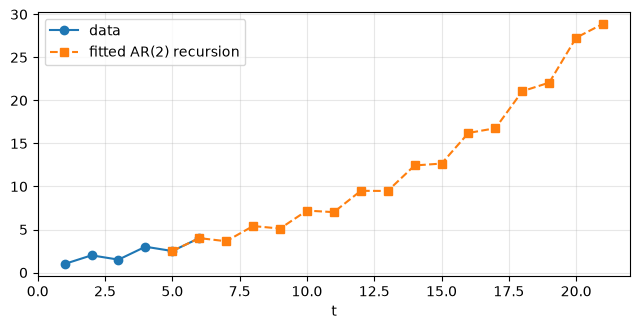

In [2]:
Y = np.array([1.0, 2.0, 1.5, 3.0, 2.5, 4.0])
yv = Y[2:]
X = np.column_stack([np.ones(4), Y[1:5], Y[0:4]])
print("X =\n", X)
print("X'X =\n", X.T @ X)
print("X'y =", X.T @ yv)

beta = np.linalg.solve(X.T @ X, X.T @ yv)
print("beta_hat =", np.round(beta, 3))
print("fitted values:", np.round(X @ beta, 3), " residuals:", np.round(yv - X @ beta, 3))

roots = np.roots([-beta[2], -beta[1], 1.0])      # 1 - b1 z - b2 z^2 = 0
print("roots of 1 - b1 z - b2 z^2:", np.round(roots, 3), " moduli:", np.round(np.abs(roots), 3))
print("stationary?", bool(np.all(np.abs(roots) > 1)))

# simulate 15 steps ahead from last two values
f = list(Y[-2:])
for _ in range(15):
    f.append(beta[0] + beta[1] * f[-1] + beta[2] * f[-2])
plt.figure(figsize=(6.5, 3.4))
plt.plot(range(1, 7), Y, "o-", label="data")
plt.plot(range(5, 5 + len(f)), f, "s--", label="fitted AR(2) recursion")
plt.legend(); plt.grid(alpha=0.3); plt.xlabel("t"); plt.tight_layout(); plt.show()

All matrices and coefficients match the note. With four equations and three unknowns this is essentially interpolation (residuals are small), and the implied recursion has roots inside the unit circle, so forecasts explode. This shows only the mechanics of regression-style AR estimation; stability and out-of-sample behavior must be checked before trusting a fit.

## 3. A design matrix without enough variation

If the series is $1,2,3,\ldots$, the columns $(1, Y_{t-1}, Y_{t-2})$ are linearly dependent (here $Y_{t-1}-Y_{t-2}=1$ at every $t$, so the lag-2 column equals the lag-1 column minus the constant column), so $\mathbf X^\top\mathbf X$ is singular and coefficients are not identified.

In [3]:
Y2 = np.arange(1.0, 9.0)
X2 = np.column_stack([np.ones(len(Y2) - 2), Y2[1:-1], Y2[:-2]])
print("rank of X:", np.linalg.matrix_rank(X2), "of", X2.shape[1], "columns")
print("det(X'X) =", np.linalg.det(X2.T @ X2).round(10))
print("singular values:", np.round(np.linalg.svd(X2, compute_uv=False), 4))
b, *_ = np.linalg.lstsq(X2, Y2[2:], rcond=None)
print("minimum-norm lstsq solution:", np.round(b, 4), "(one of infinitely many exact fits)")

rank of X: 2 of 3 columns
det(X'X) = 0.0
singular values: [15.3185  1.1586  0.    ]
minimum-norm lstsq solution: [ 1.  1. -0.] (one of infinitely many exact fits)


The design has rank 2 rather than 3 and $\det(\mathbf X^\top\mathbf X)=0$, so the inverse in the OLS formula does not exist. Inspecting the design matrix (and using a stable solver such as least squares) is part of the model-fitting step.

## 4. Order selection on simulated data

We simulate $Y_t=0.5Y_{t-1}-0.3Y_{t-2}+0.4\varepsilon_{t-1}+\varepsilon_t$ (an ARMA(2,1)), then fit ARMA($p,q$) candidates by maximum likelihood (MA terms are latent, so OLS is not valid) and compare AIC, AICc, and BIC.

In [4]:
rng = np.random.default_rng(99)
n = 400
e = rng.normal(size=n + 200)
y = np.zeros(n + 200)
for t in range(2, n + 200):
    y[t] = 0.5 * y[t - 1] - 0.3 * y[t - 2] + 0.4 * e[t - 1] + e[t]
y = y[200:]

rows = []
for p in range(0, 4):
    for q in range(0, 3):
        res = ARIMA(y, order=(p, 0, q)).fit()
        k = res.params.size
        aicc = res.aic + 2 * k * (k + 1) / (len(y) - k - 1)
        rows.append((p, q, k, res.aic, aicc, res.bic))
rows.sort(key=lambda r: r[4])
print(" p q  k     AIC    AICc     BIC")
for p, q, k, aic, aicc, bic in rows[:6]:
    print(f"{p:2d}{q:2d}{k:3d} {aic:8.2f}{aicc:8.2f}{bic:8.2f}")

best_aic = min(rows, key=lambda r: r[3])
best_bic = min(rows, key=lambda r: r[5])
print("best by AIC:", best_aic[:2], "  best by BIC:", best_bic[:2], "  truth: (2, 1)")

fit = ARIMA(y, order=(2, 0, 1)).fit()
print(fit.params.round(3).to_string() if hasattr(fit.params, "to_string") else np.round(fit.params, 3))

 p q  k     AIC    AICc     BIC
 0 2  4  1169.38 1169.48 1185.34
 1 2  5  1170.25 1170.40 1190.21
 2 2  6  1172.23 1172.45 1196.18
 3 2  7  1172.17 1172.45 1200.11
 2 1  5  1173.65 1173.81 1193.61
 3 0  5  1174.54 1174.69 1194.49
best by AIC: (0, 2)   best by BIC: (0, 2)   truth: (2, 1)
[ 0.051  0.586 -0.261  0.356  1.071]


The criteria rank the candidates in a similar way, with BIC typically choosing a smaller model than AIC. The true ARMA(2,1) is not necessarily ranked first: a low-order MA can approximate an ARMA(2,1) well, so criteria differences of a few units are not decisive and order should not be chosen from a single number. Fitting the true ARMA(2,1) still recovers coefficients near $(0.5,-0.3,0.4)$ (printed order: constant, AR1, AR2, MA1, innovation variance).

## 5. Residual diagnostics

Residuals $\hat\varepsilon_t=y_t-\hat y_{t|t-1}$ should show no remaining autocorrelation. The Ljung-Box statistic is $Q(m)=T(T+2)\sum_{h=1}^{m}\hat\rho(h)^2/(T-h)$. We compare the adequate ARMA(2,1) with an under-fitted AR(1).

ARMA(2,1)              Q(10) manual=  7.742  statsmodels=  7.742  p-value=0.6541   AIC=1173.7
AR(1) (under-fitted)   Q(10) manual= 76.703  statsmodels= 76.703  p-value=0.0000   AIC=1262.0


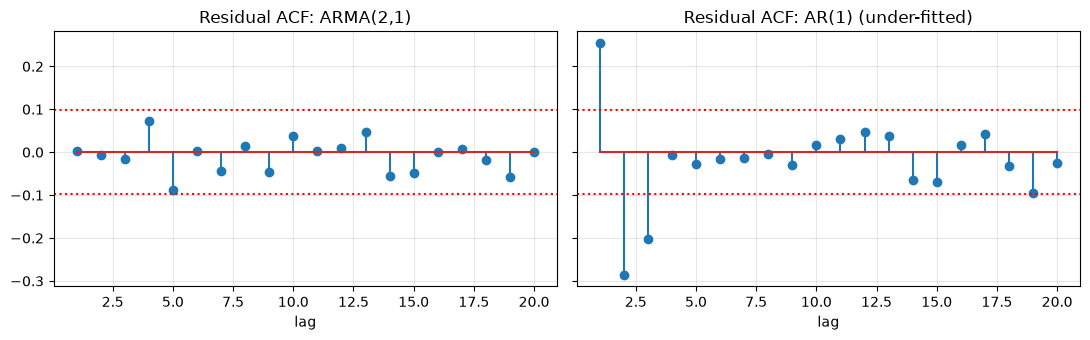

In [5]:
fit_good = ARIMA(y, order=(2, 0, 1)).fit()
fit_bad = ARIMA(y, order=(1, 0, 0)).fit()

# manual Q(10) check against statsmodels
def ljung_q(res, m):
    T = len(res)
    r = acf(res, nlags=m, fft=False)[1:]
    return T * (T + 2) * np.sum(r**2 / (T - np.arange(1, m + 1)))

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5), sharey=True)
for a, (name, f_) in zip(ax, (("ARMA(2,1)", fit_good), ("AR(1) (under-fitted)", fit_bad))):
    res = f_.resid
    q_manual = ljung_q(res, 10)
    lb = acorr_ljungbox(res, lags=[10], return_df=True)
    print(f"{name:22s} Q(10) manual={q_manual:7.3f}  statsmodels={float(lb['lb_stat'].iloc[0]):7.3f}  "
          f"p-value={float(lb['lb_pvalue'].iloc[0]):.4f}   AIC={f_.aic:.1f}")
    a.stem(range(1, 21), acf(res, nlags=20, fft=False)[1:])
    a.axhline(1.96 / np.sqrt(len(res)), color="r", ls=":"); a.axhline(-1.96 / np.sqrt(len(res)), color="r", ls=":")
    a.set_title(f"Residual ACF: {name}"); a.set_xlabel("lag"); a.grid(alpha=0.3)
plt.tight_layout(); plt.show()

The hand-computed $Q(10)$ matches statsmodels. The adequate model leaves residuals that are statistically indistinguishable from white noise, while the AR(1) leaves significant autocorrelation, the signal that a dynamic term is missing. A good IC value paired with poor residuals is a warning, not a victory.

## 6. Chronological holdout and baselines

Model selection is incomplete until forecasts are evaluated on future-like data. We fit on the first 320 observations and forecast the last 80 one step ahead (re-using the fitted parameters but updating the data), comparing the ARMA(2,1), the AR(1), the naive last-value forecast, and the training mean with MAE and RMSE.

model                MAE    RMSE


ARMA(2,1)           0.787  0.949
AR(1)               0.863  1.015
naive last value    0.916  1.137
training mean       1.026  1.254


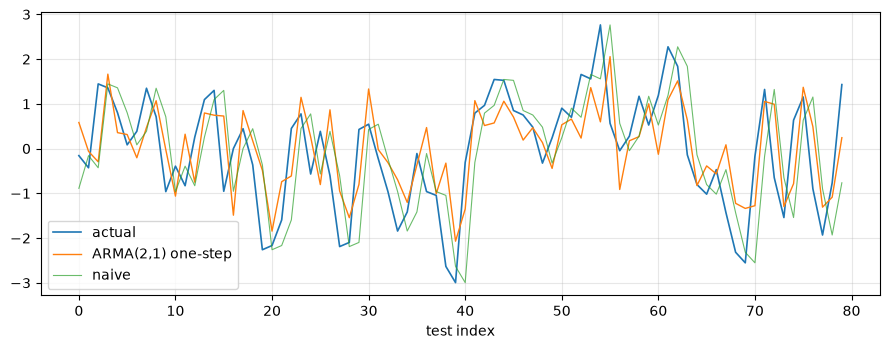

In [6]:
train, test = y[:320], y[320:]

def one_step(order):
    res = ARIMA(train, order=order).fit()
    ext = res.append(test, refit=False)          # parameters fixed, state updated with new data
    pred = ext.predict(start=320, end=len(y) - 1)  # one-step-ahead
    return np.asarray(pred)

preds = {
    "ARMA(2,1)": one_step((2, 0, 1)),
    "AR(1)": one_step((1, 0, 0)),
    "naive last value": np.concatenate([[train[-1]], test[:-1]]),
    "training mean": np.full(len(test), train.mean()),
}
print(f"{'model':18s}   MAE    RMSE")
for name, pr in preds.items():
    err = test - pr
    print(f"{name:18s} {np.mean(np.abs(err)):6.3f} {np.sqrt(np.mean(err**2)):6.3f}")

plt.figure(figsize=(9, 3.6))
plt.plot(test, label="actual", lw=1.2)
plt.plot(preds["ARMA(2,1)"], label="ARMA(2,1) one-step", lw=1)
plt.plot(preds["naive last value"], label="naive", lw=0.8, alpha=0.7)
plt.legend(); plt.grid(alpha=0.3); plt.xlabel("test index"); plt.tight_layout(); plt.show()

The ARMA(2,1) has the lowest errors, followed by the AR(1); both beat the naive last value, which is worse here because the process is mean-reverting and the last value carries the last shock's noise. Reporting a baseline alongside the chosen model is what makes the comparison meaningful.

**Takeaways.** Use information criteria to narrow candidates, inspect the design matrix and the implied roots, verify residual whiteness, and confirm improvement chronologically against simple baselines.